# Bank marketing, part 1: testing what really drives conversion

**Business question.** A Portuguese bank phoned clients to sell a term deposit. Before building any model
(notebook 02), this notebook checks four beliefs a marketing manager might hold, using proper statistical tests:

1. Do mobile contacts convert better than landline contacts?
2. Do clients who said yes in a previous campaign convert better?
3. Does conversion fall the more times the same client is called in one campaign?
4. Does the day of the week matter?

**How each question is handled**

- the hypothesis in plain English,
- the conversion rates with 95% confidence intervals,
- a suitable test (two-proportion z-test, chi-square test, or logistic regression for a trend),
- an **effect size**, because with 41,000 rows almost any difference is "statistically significant",
- a check of whether the result survives once the *time period* is taken into account.

**One warning that applies to everything below.** This is observational data, not an experiment. Nobody
randomly assigned clients to mobile or landline, or to one call or five. The bank changed how it worked while
the 2008 financial crisis unfolded, so contact channel, month and the economic climate are tangled together
in time. The differences found here are **associations**, not proof of cause and effect.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import (
    proportion_confint,           # confidence interval for one rate
    proportions_ztest,            # z-test comparing two rates
    confint_proportions_2indep,   # confidence interval for the difference of two rates
)

# Paths are relative to this notebook, so the project runs on any machine
DATA_DIR = Path("..") / "data"
IMG_DIR = Path("..") / "images"
IMG_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 120)

One small block of chart settings, reused by every chart, keeps the look consistent:
three colours only (navy for the main series, orange for the highlight, grey for context).

In [2]:
NAVY, ORANGE, GREY = "#1f3a5f", "#d9822b", "#9aa5b1"

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 150,              # resolution of the PNG files
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,        # remove the box around the chart
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,          # grid lines behind the bars
    "grid.color": "#e5e8eb",
})

## 2. Load and prepare the data

The file is semicolon-separated. The preparation follows the same rules as notebook 02:

- drop the 12 exact duplicate rows,
- keep the text `"unknown"` as its own category (no guessing of missing values),
- turn the target `y` (yes/no) into a 1/0 column called `subscribed`, so that its mean is the conversion rate.

In [3]:
raw = pd.read_csv(DATA_DIR / "bank-additional-full.csv", sep=";")
print("Rows and columns in the raw file:", raw.shape)
print("Exact duplicate rows:", raw.duplicated().sum())

df = raw.drop_duplicates().reset_index(drop=True)

# Dots in column names (emp.var.rate) get in the way of model formulas, so use underscores
df.columns = [c.replace(".", "_") for c in df.columns]

df["subscribed"] = (df["y"] == "yes").astype(int)

print("Rows after removing duplicates:", len(df))
print("Subscribers:", df["subscribed"].sum())
print(f"Overall conversion rate: {df['subscribed'].mean():.2%}")

Rows and columns in the raw file: (41188, 21)
Exact duplicate rows: 12
Rows after removing duplicates: 41176
Subscribers: 4639
Overall conversion rate: 11.27%


### Recover the year

The file has a `month` column but no year. The official notes say the rows are in date order
(May 2008 to November 2010), so the year can be recovered: every time the month number goes *down*
from one row to the next (for example December to March), a new year has started.
This is only used to split the data into periods; no new information is added.

In [4]:
month_number = df["month"].map({"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
                                "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12})

# diff() < 0 is True on the first row of each new year; cumsum() counts how many new years have started
df["year"] = 2008 + (month_number.diff() < 0).cumsum()

by_year = df.groupby("year").agg(
    contacts=("subscribed", "size"),
    conversion_rate=("subscribed", "mean"),
    share_mobile=("contact", lambda s: (s == "cellular").mean()),
    mean_euribor=("euribor3m", "mean"),
)
by_year.round(3)

,contacts,conversion_rate,share_mobile,mean_euribor
year,,,,
2008,27682,0.048,0.505,4.817
2009,11436,0.195,0.918,1.232
2010,2058,0.521,0.811,0.813


**This table explains most of what follows.** The three years look nothing alike:

- 2008 holds about two thirds of all calls and converts very poorly; 2010 is a small year with a very high conversion rate.
- Interest rates (Euribor) collapsed from 2008 to 2009 as the financial crisis hit.
- The mix of mobile and landline contacts also changed between years.

So any factor that is more common in the later years will *look* good, whether or not it really helps.
This is called **confounding**, and each test below checks for it.

### Two helper functions

`rate_table` computes, for each group, the number of contacts, the conversion rate and a 95% confidence
interval (Wilson method, the standard choice for percentages). `plot_rates` draws the rates as bars with the
interval as an error bar.

In [5]:
def rate_table(data, group_col):
    # Conversion rate per group with a 95% Wilson confidence interval.
    table = data.groupby(group_col, observed=True)["subscribed"].agg(contacts="size", subscribers="sum")
    table["rate"] = table["subscribers"] / table["contacts"]
    low, high = proportion_confint(table["subscribers"], table["contacts"], alpha=0.05, method="wilson")
    table["ci_low"] = low
    table["ci_high"] = high
    return table


def plot_rates(ax, table, colors, title):
    # Bar chart of conversion rates (in %) with confidence-interval error bars.
    rates = table["rate"] * 100
    # error bars are given as distances below and above the bar top
    errors = [rates - table["ci_low"] * 100, table["ci_high"] * 100 - rates]
    labels = [str(label) for label in table.index]
    ax.bar(labels, rates, yerr=errors, color=colors, capsize=4, ecolor="#333333")
    for i, value in enumerate(rates):
        ax.text(i, table["ci_high"].iloc[i] * 100 + 0.6, f"{value:.1f}%", ha="center", fontsize=9)
    ax.set_ylabel("Conversion rate (%)")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)

## 3. Question 1: do mobile contacts convert better than landline?

**Hypothesis in plain English.** *Null hypothesis:* the conversion rate is the same whether the client was
reached on a mobile (`cellular`) or a landline (`telephone`). *Alternative:* the two rates differ.

**Test.** Two groups and a yes/no outcome, so a **two-proportion z-test**.

In [6]:
channel = rate_table(df, "contact")
channel.round(4)

,contacts,subscribers,rate,ci_low,ci_high
contact,,,,,
cellular,26135,3852,0.1474,0.1431,0.1517
telephone,15041,787,0.0523,0.0489,0.0560


In [7]:
mobile = channel.loc["cellular"]
landline = channel.loc["telephone"]

# Two-proportion z-test: could a gap this big appear by chance if the true rates were equal?
z_stat, p_value = proportions_ztest(
    count=[mobile["subscribers"], landline["subscribers"]],
    nobs=[mobile["contacts"], landline["contacts"]],
)

# Effect sizes: how big is the gap?
diff = mobile["rate"] - landline["rate"]                     # in percentage points
diff_low, diff_high = confint_proportions_2indep(
    mobile["subscribers"], mobile["contacts"], landline["subscribers"], landline["contacts"])
risk_ratio = mobile["rate"] / landline["rate"]               # "x times as likely"
# Cohen's h: a standard effect size for two percentages (0.2 small, 0.5 medium, 0.8 large)
cohens_h = 2 * np.arcsin(np.sqrt(mobile["rate"])) - 2 * np.arcsin(np.sqrt(landline["rate"]))

print(f"z = {z_stat:.1f}, p-value = {p_value:.1e}")
print(f"Difference: {diff * 100:.1f} percentage points (95% CI {diff_low * 100:.1f} to {diff_high * 100:.1f})")
print(f"Risk ratio: {risk_ratio:.2f}")
print(f"Cohen's h: {cohens_h:.2f}")

z = 29.4, p-value = 1.1e-189
Difference: 9.5 percentage points (95% CI 8.9 to 10.1)
Risk ratio: 2.82
Cohen's h: 0.33


**Reading the result.** Across the whole file, mobile contacts converted at 14.7% and landline contacts at
5.2%: a gap of 9.5 percentage points, or 2.8 times the rate. The p-value is essentially zero, and the effect
size (Cohen's h = 0.33) is small-to-medium, so this is not just a large-sample artefact.

**But is it the phone, or the period?** Look at the same comparison inside each year.

In [8]:
channel_by_year = df.groupby(["year", "contact"])["subscribed"].agg(contacts="size", rate="mean").unstack("contact")
channel_by_year.round(3)

contacts               rate          
contact cellular telephone cellular telephone
year                                         
2008       13970     13712    0.057     0.039
2009       10495       941    0.199     0.147
2010        1670       388    0.577     0.284

In [9]:
# One z-test per year, to see whether the mobile advantage holds inside each period
for year, part in df.groupby("year"):
    t = rate_table(part, "contact")
    z, p = proportions_ztest(t["subscribers"], t["contacts"])
    gap = (t.loc["cellular", "rate"] - t.loc["telephone", "rate"]) * 100
    print(f"{year}: mobile {t.loc['cellular', 'rate']:.1%} vs landline {t.loc['telephone', 'rate']:.1%}"
          f"  -> gap {gap:+.1f} points, p-value = {p:.3g}")

2008: mobile 5.7% vs landline 3.9%  -> gap +1.8 points, p-value = 3.35e-12
2009: mobile 19.9% vs landline 14.7%  -> gap +5.2 points, p-value = 0.000101
2010: mobile 57.7% vs landline 28.4%  -> gap +29.3 points, p-value = 2.17e-25


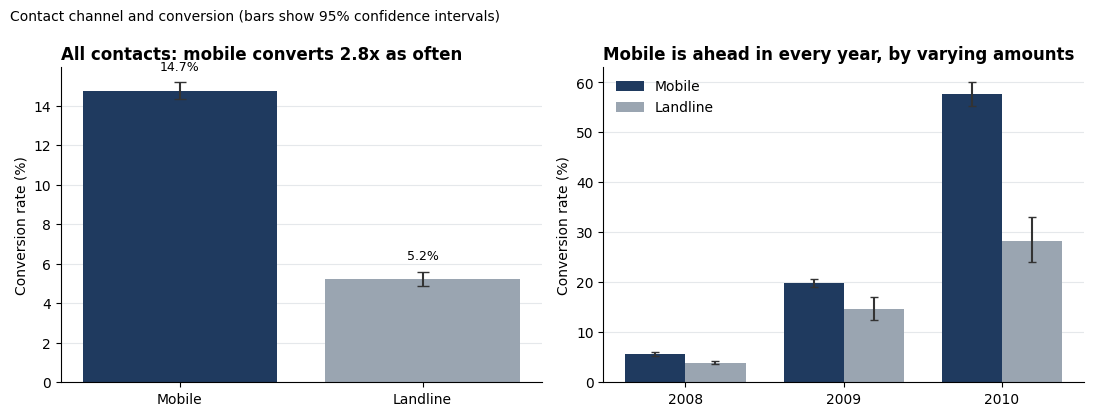

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

plot_rates(axes[0], channel.rename(index={"cellular": "Mobile", "telephone": "Landline"}),
           [NAVY, GREY], "All contacts: mobile converts 2.8x as often")

# Right panel: the same comparison within each year
years = sorted(df["year"].unique())
x = np.arange(len(years))
for offset, (contact, label, color) in enumerate([("cellular", "Mobile", NAVY), ("telephone", "Landline", GREY)]):
    t = rate_table(df[df["contact"] == contact], "year")
    rates = t["rate"] * 100
    axes[1].bar(x + (offset - 0.5) * 0.38, rates, width=0.38, color=color, label=label,
                yerr=[rates - t["ci_low"] * 100, t["ci_high"] * 100 - rates], capsize=3, ecolor="#333333")
axes[1].set_xticks(x)
axes[1].set_xticklabels(years)
axes[1].set_ylabel("Conversion rate (%)")
axes[1].set_title("Mobile is ahead in every year, by varying amounts")
axes[1].grid(axis="x", visible=False)
axes[1].legend(frameon=False)

fig.suptitle("Contact channel and conversion (bars show 95% confidence intervals)", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
fig.savefig(IMG_DIR / "01_channel_overall_vs_by_year.png")
plt.show()

**What changed.** Mobile contacts did better than landline contacts in each of the three years, so the
direction of the result holds. The size does not: the gap is 1.8 points in 2008, 5.2 points in 2009 and
29.3 points in 2010 (a small year with only 388 landline contacts). The headline gap of 9.5 points is partly a
period effect: 2008, the weakest year, was half landline (50.5% mobile), while 2009 and 2010 were mostly mobile.

### Adjusting for the economy with logistic regression

A second way to take the period into account is a **logistic regression**, a model for yes/no outcomes that
can hold several factors at once. Its results are read as **odds ratios**: 1 means no difference,
2 means the odds of subscribing are doubled, 0.5 means halved.

Two models are compared:

- *unadjusted*: channel only,
- *adjusted*: channel plus the five economic indicators in the file (employment variation, consumer prices,
  consumer confidence, Euribor rate, number of employed). These indicators describe the economic climate on the
  day of the call, so they act as a stand-in for "when".

The helper below fits both and returns the odds ratio for the factor of interest. It is reused for questions 2 and 3.

In [11]:
ECONOMY = "emp_var_rate + cons_price_idx + cons_conf_idx + euribor3m + nr_employed"

def odds_ratio(formula, term):
    # Fit a logistic regression and return the odds ratio, its 95% CI and p-value for one term.
    model = smf.logit(formula, data=df).fit(disp=0)      # disp=0 hides the fitting log
    ci_low, ci_high = np.exp(model.conf_int().loc[term])  # exp() turns log-odds into odds ratios
    return {"odds_ratio": np.exp(model.params[term]), "ci_low": ci_low, "ci_high": ci_high,
            "p_value": model.pvalues[term]}

def before_after(term, label):
    # Odds ratio for `term` without and with the economic indicators in the model.
    rows = {
        (label, "unadjusted"): odds_ratio(f"subscribed ~ {term}", term),
        (label, "adjusted for economy"): odds_ratio(f"subscribed ~ {term} + {ECONOMY}", term),
    }
    return pd.DataFrame(rows).T

df["mobile"] = (df["contact"] == "cellular").astype(int)

or_channel = before_after("mobile", "Mobile vs landline")
or_channel.round(3)

odds_ratio  ci_low  ci_high  p_value
Mobile vs landline unadjusted                 3.131   2.892     3.39      0.0
                   adjusted for economy       2.861   2.573     3.18      0.0

**Reading the result.** Without adjustment the odds of subscribing are 3.13 times higher for mobile contacts.
With the economic indicators in the model the odds ratio is 2.86 (95% CI 2.57 to 3.18). The association
shrinks only a little, so the mobile advantage is not simply a by-product of the economic climate.

Two cautions. An odds ratio is not the same as "times as likely" (the risk ratio above was 2.82; the two are
close here only because conversion is rare). And the adjustment covers the economy only: the data cannot say
*why* mobile contacts convert better. People reachable on a mobile may differ from people reachable on a
landline in ways the file does not record. (p-values printed as 0.0 in these tables are smaller than 0.0005.)

## 4. Question 2: do clients who said yes before convert better?

`poutcome` records the result of the previous campaign for that client: `success`, `failure`, or
`nonexistent` (the client was never part of a previous campaign).

**Hypothesis.** *Null:* the conversion rate is the same in all three groups. *Alternative:* at least one differs.

**Test.** Three groups and a yes/no outcome, so a **chi-square test of independence**, with **Cramér's V** as
the effect size (0 = no relationship, 1 = perfect; roughly 0.1 small, 0.3 medium, 0.5 large for a table like this).

In [12]:
previous = rate_table(df, "poutcome").loc[["nonexistent", "failure", "success"]]
previous.round(4)

,contacts,subscribers,rate,ci_low,ci_high
poutcome,,,,,
nonexistent,35551,3140,0.0883,0.0854,0.0913
failure,4252,605,0.1423,0.1321,0.1531
success,1373,894,0.6511,0.6255,0.6759


In [13]:
def chi_square(data, group_col):
    # Chi-square test of independence between a grouping column and the outcome, plus Cramér's V.
    counts = pd.crosstab(data[group_col], data["subscribed"])
    chi2, p, dof, expected = stats.chi2_contingency(counts)
    # Cramér's V = sqrt(chi2 / (n * (smaller table dimension - 1))); here the outcome has 2 levels, so that is 1
    cramers_v = np.sqrt(chi2 / counts.to_numpy().sum())
    return chi2, p, dof, cramers_v

chi2, p, dof, v = chi_square(df, "poutcome")
print(f"chi-square = {chi2:.0f} on {dof} degrees of freedom, p-value = {p:.1e}")
print(f"Cramér's V = {v:.2f}")

# The comparison a manager cares about most: previous success against never contacted
success, never = previous.loc["success"], previous.loc["nonexistent"]
d_low, d_high = confint_proportions_2indep(success["subscribers"], success["contacts"],
                                           never["subscribers"], never["contacts"])
print(f"Previous success vs no previous campaign: {success['rate']:.1%} vs {never['rate']:.1%}, "
      f"difference {100 * (success['rate'] - never['rate']):.1f} points "
      f"(95% CI {100 * d_low:.1f} to {100 * d_high:.1f}), risk ratio {success['rate'] / never['rate']:.1f}")

chi-square = 4230 on 2 degrees of freedom, p-value = 0.0e+00
Cramér's V = 0.32
Previous success vs no previous campaign: 65.1% vs 8.8%, difference 56.3 points (95% CI 53.7 to 58.8), risk ratio 7.4


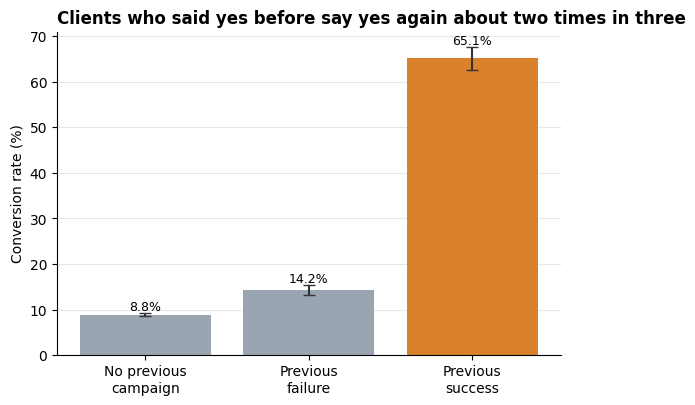

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
plot_rates(ax, previous.rename(index={"nonexistent": "No previous\ncampaign", "failure": "Previous\nfailure",
                                      "success": "Previous\nsuccess"}),
           [GREY, GREY, ORANGE], "Clients who said yes before say yes again about two times in three")
fig.savefig(IMG_DIR / "02_conversion_by_previous_outcome.png")
plt.show()

Before adjusting, a quick look at *when* clients with a previous success were called.

In [15]:
df.groupby("year").agg(
    contacts=("subscribed", "size"),
    share_with_previous_success=("poutcome", lambda s: (s == "success").mean()),
    share_with_any_previous_campaign=("poutcome", lambda s: (s != "nonexistent").mean()),
).round(3)

,contacts,share_with_previous_success,share_with_any_previous_campaign
year,,,
2008,27682,0.001,0.027
2009,11436,0.060,0.321
2010,2058,0.315,0.590


Now the same adjustment as before: does the advantage survive once the economic climate is held constant?
The reference group is "no previous campaign".

In [16]:
df["prev_success"] = (df["poutcome"] == "success").astype(int)
df["prev_failure"] = (df["poutcome"] == "failure").astype(int)

# Both indicators go in the same model, so each is compared with "no previous campaign"
rows = {}
for term, label in [("prev_success", "Previous success vs none"), ("prev_failure", "Previous failure vs none")]:
    rows[(label, "unadjusted")] = odds_ratio("subscribed ~ prev_success + prev_failure", term)
    rows[(label, "adjusted for economy")] = odds_ratio(f"subscribed ~ prev_success + prev_failure + {ECONOMY}", term)
or_previous = pd.DataFrame(rows).T
or_previous.round(3)

odds_ratio  ci_low  ci_high  p_value
Previous success vs none unadjusted                19.265  17.140   21.653      0.0
                         adjusted for economy       4.153   3.641    4.736      0.0
Previous failure vs none unadjusted                 1.712   1.559    1.880      0.0
                         adjusted for economy       0.649   0.586    0.720      0.0

**Reading the result.** This is the largest effect in the notebook. Clients with a previous success converted
at 65.1%, against 8.8% for clients with no previous campaign: 56.3 points higher (95% CI 53.7 to 58.8), or
7.4 times the rate. Cramér's V is 0.32, a medium-sized relationship across the whole table, which is notable
because only 1,373 of 41,176 contacts (3.3%) are in the "success" group.

**What changed after adjustment.** The odds ratio for a previous success falls from 19.3 to 4.2. It is still
a strong effect, but most of the raw figure came from *when* these clients were called: follow-up calls to
previous subscribers happened mainly in 2009 and 2010, when everybody converted more often.

The "previous failure" group shows why adjustment matters. Unadjusted, these clients look *better* than
never-contacted clients (odds ratio 1.71). After adjustment they look *worse* (odds ratio 0.65). The raw
comparison was misleading because clients with any campaign history were mostly called in the high-conversion
period.

## 5. Question 3: does conversion fall as the same client is called more often?

`campaign` is the number of times the client was contacted during this campaign, including the last call.

**Hypothesis.** *Null:* the conversion rate does not depend on the number of calls. *Alternative:* there is a
trend (a "dose-response" pattern: more calls, lower conversion).

**Test.** The groups are ordered (1, 2, 3, ... calls), so a plain chi-square test would waste that information.
A **logistic regression with the number of calls as a number** tests for a trend directly and gives an effect
size that is easy to say out loud: the change in odds *per extra call*.

Very high call counts are rare (the maximum is 56), so counts above 10 are grouped as 10 to stop a handful of
extreme rows from steering the result.

In [17]:
df["calls"] = df["campaign"].clip(upper=10)     # 10 now means "10 or more"

calls = rate_table(df, "calls")
calls.round(4)

,contacts,subscribers,rate,ci_low,ci_high
calls,,,,,
1,17634,2299,0.1304,0.1255,0.1354
2,10568,1211,0.1146,0.1087,0.1208
3,5340,574,0.1075,0.0995,0.1161
4,2650,249,0.0940,0.0834,0.1057
5,1599,120,0.0750,0.0631,0.0890
6,979,75,0.0766,0.0616,0.0950
7,629,38,0.0604,0.0443,0.0818
8,400,17,0.0425,0.0267,0.0670
9,283,17,0.0601,0.0378,0.0941


In [18]:
or_calls = before_after("calls", "Each extra call")
or_calls.round(4)

odds_ratio  ci_low  ci_high  p_value
Each extra call unadjusted                0.8707  0.8542   0.8875      0.0
                adjusted for economy      0.9495  0.9303   0.9691      0.0

In [19]:
# How unevenly were calls spread over the years?
df.groupby("year")["campaign"].agg(mean_calls="mean", share_with_4_or_more=lambda s: (s >= 4).mean()).round(3)

,mean_calls,share_with_4_or_more
year,,
2008,2.800,0.209
2009,2.126,0.142
2010,1.905,0.103


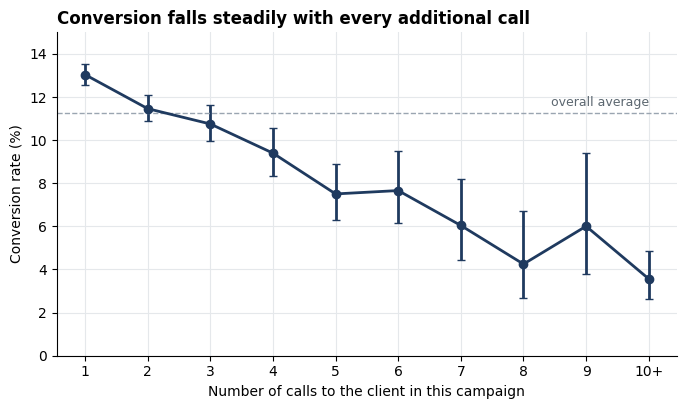

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.2))
rates = calls["rate"] * 100
labels = [str(n) for n in calls.index[:-1]] + ["10+"]
ax.errorbar(labels, rates, yerr=[rates - calls["ci_low"] * 100, calls["ci_high"] * 100 - rates],
            color=NAVY, marker="o", capsize=3, linewidth=2)
ax.axhline(df["subscribed"].mean() * 100, color=GREY, linestyle="--", linewidth=1)
ax.text(len(labels) - 1, df["subscribed"].mean() * 100 + 0.3, "overall average", color="#5c6770", ha="right", fontsize=9)
ax.set_ylim(0, 15)
ax.set_xlabel("Number of calls to the client in this campaign")
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion falls steadily with every additional call")
fig.savefig(IMG_DIR / "03_conversion_by_number_of_calls.png")
plt.show()

**Reading the result.** Conversion falls from 13.0% on the first call to 3.6% for clients called ten or more
times. Unadjusted, each extra call is associated with 13% lower odds of subscribing (odds ratio 0.871,
95% CI 0.854 to 0.888).

**What changed after adjustment.** With the economic indicators in the model the odds ratio moves to 0.950:
about 5% lower odds per extra call instead of 13%. Roughly two thirds of the raw trend is explained by timing:
repeated calling was most common in 2008 (21% of contacts were on a fourth or later call, against 10% in 2010),
which was also the year with the lowest conversion.

**A second caution, specific to this column.** Each row stores the *final* number of calls. Clients who say
yes are not called again, so clients who were easy to convince end up with low call counts by construction.
The downward trend therefore mixes two things: persistent calling having less and less return, and "difficult"
clients accumulating calls. The data cannot separate them. What can be said safely: a client already called
four or more times without success is a poor prospect.

## 6. Question 4: does the day of the week matter?

**Hypothesis.** *Null:* the conversion rate is the same on all five working days. *Alternative:* at least one day differs.

**Test.** Five groups, yes/no outcome: chi-square test with Cramér's V.
This question is included on purpose as a contrast with the first three.

In [21]:
weekday = rate_table(df, "day_of_week").loc[["mon", "tue", "wed", "thu", "fri"]]
weekday.round(4)

,contacts,subscribers,rate,ci_low,ci_high
day_of_week,,,,,
mon,8512,847,0.0995,0.0933,0.1060
tue,8086,953,0.1179,0.1110,0.1251
wed,8134,949,0.1167,0.1099,0.1238
thu,8618,1044,0.1211,0.1144,0.1282
fri,7826,846,0.1081,0.1014,0.1152


In [22]:
chi2, p, dof, v = chi_square(df, "day_of_week")
print(f"chi-square = {chi2:.1f} on {dof} degrees of freedom, p-value = {p:.1e}")
print(f"Cramér's V = {v:.3f}")
print(f"Best day minus worst day: {(weekday['rate'].max() - weekday['rate'].min()) * 100:.1f} percentage points")

chi-square = 26.1 on 4 degrees of freedom, p-value = 3.1e-05
Cramér's V = 0.025
Best day minus worst day: 2.2 percentage points


**Reading the result.** The p-value is 0.00003, far below the usual 0.05 threshold, so the result is
"statistically significant". But Cramér's V is 0.025, which is negligible, and the best day (Thursday, 12.1%)
is only 2.2 percentage points above the worst (Monday, 10.0%).

This is the lesson of large samples: **a tiny p-value means the difference is unlikely to be exactly zero, not
that it is large or useful.** With 41,176 rows, even trivial differences pass a significance test. Nobody
should rebuild the call schedule around this result, especially as it is observational and the bank may have
called different kinds of clients on different days.

## 7. All four questions side by side

The chart below shows every odds ratio before and after adjusting for the economic indicators.
The further a point is from the dashed line at 1, the stronger the association.

In [23]:
all_or = pd.concat([or_channel, or_previous, or_calls])
all_or.round(3)

odds_ratio  ci_low  ci_high  p_value
Mobile vs landline       unadjusted                 3.131   2.892    3.390      0.0
                         adjusted for economy       2.861   2.573    3.180      0.0
Previous success vs none unadjusted                19.265  17.140   21.653      0.0
                         adjusted for economy       4.153   3.641    4.736      0.0
Previous failure vs none unadjusted                 1.712   1.559    1.880      0.0
                         adjusted for economy       0.649   0.586    0.720      0.0
Each extra call          unadjusted                 0.871   0.854    0.888      0.0
                         adjusted for economy       0.950   0.930    0.969      0.0

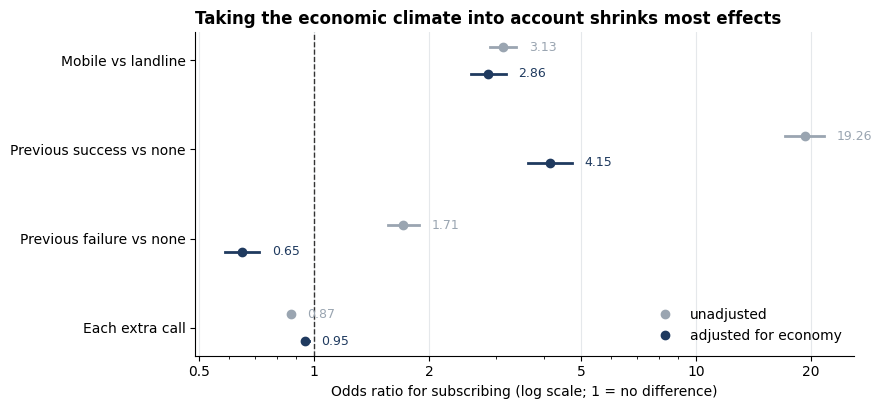

In [24]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
labels = list(dict.fromkeys(all_or.index.get_level_values(0)))   # unique labels, original order

for i, label in enumerate(labels):
    for version, color, shift in [("unadjusted", GREY, 0.15), ("adjusted for economy", NAVY, -0.15)]:
        row = all_or.loc[(label, version)]
        y_pos = len(labels) - 1 - i + shift
        ax.plot([row["ci_low"], row["ci_high"]], [y_pos, y_pos], color=color, linewidth=2)
        ax.plot(row["odds_ratio"], y_pos, "o", color=color, label=version if i == 0 else None)
        ax.text(row["ci_high"] * 1.08, y_pos, f"{row['odds_ratio']:.2f}", va="center", fontsize=9, color=color)

ax.axvline(1, color="#333333", linestyle="--", linewidth=1)
ax.set_xscale("log")                       # odds ratios are multiplicative, so a log scale is the fair one
ax.set_xticks([0.5, 1, 2, 5, 10, 20])
ax.set_xticklabels(["0.5", "1", "2", "5", "10", "20"])
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels[::-1])
ax.set_xlabel("Odds ratio for subscribing (log scale; 1 = no difference)")
ax.set_title("Taking the economic climate into account shrinks most effects")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
fig.savefig(IMG_DIR / "04_odds_ratios_before_after_adjustment.png")
plt.show()

## 8. Summary

| Question | Raw result | Effect size | After taking the period into account | Verdict |
|---|---|---|---|---|
| Mobile vs landline | 14.7% vs 5.2% | +9.5 points, risk ratio 2.8, Cohen's h 0.33 | Odds ratio 3.13 -> 2.86; mobile ahead in every year | Real and fairly robust association |
| Previous success | 65.1% vs 8.8% (no previous campaign) | +56.3 points, risk ratio 7.4, Cramér's V 0.32 | Odds ratio 19.3 -> 4.2 | Strongest signal, but the raw figure overstates it |
| Previous failure | 14.2% vs 8.8% | Odds ratio 1.71 | Odds ratio 0.65: the direction reverses | Raw comparison is misleading |
| Number of calls | 13.0% on call 1, 3.6% on call 10+ | 13% lower odds per extra call | 5% lower odds per extra call | Real trend, about a third of its raw size |
| Day of week | 10.0% to 12.1% | Cramér's V 0.025 | not needed | Significant but practically irrelevant |

**Take-aways**

1. Every one of these tests has a p-value below 0.001. The p-value alone would rank "day of week" alongside
   "previous success". The effect sizes show they are not remotely comparable.
2. The period matters as much as any client attribute: conversion was 4.8% in 2008, 19.5% in 2009 and 52.1%
   in 2010. Adjusting for the economic climate shrank three of the four tested effects and reversed one.
3. These are associations in observational data. To *prove* that, for example, calling mobiles causes more
   sales, the bank would need an experiment (randomly choosing which number to call).

Notebook 02 uses these findings to build a lead-scoring model, and takes the period problem seriously when
testing it.